# Real-space decay of the el-ph Wannier tensor (`epmatwp`)

The coarse-grid (8×8×8) convergence argument rests on the exponential localization of the Wannier-representation quantities: the coarse grid only sets the Wigner–Seitz supercell they are truncated to, and the long-range polar part is handled analytically. This plots EPW's own decay dumps from the LiF run (`datasets/LiF/decay.*`), which reduce the full `epmatwp` tensor to $\max_{m,n,\nu} |g(m,n,\nu,R)|$ per WS vector — no need to parse the 146 MB binary.

- `decay.epmate` — decay of $g$ along the **electron** axis $R_e$ (the `nrr_k` axis)
- `decay.epmatp` — decay of $g$ along the **phonon** axis $R_p$ (the `nrr_g` axis)
- `decay.H`, `decay.dynmat` — Hamiltonian and force constants, same argument for bands/phonons

Units: $R$ in Å, elements in Ry (atomic units for the dynamical matrix). What to look for: a roughly straight envelope on the semilog axis (exponential decay) that has fallen by several orders of magnitude before the supercell boundary (dashed line, $R_{\max}\approx17$ Å).

inline math: $ a^2 + b^2 $

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

lif = Path("../datasets/LiF")
files = {
    "g vs $R_e$ (epmate)": ("decay.epmate", "#2a78d6"),
    "g vs $R_p$ (epmatp)": ("decay.epmatp", "#008300"),
    "$H(R_e)$": ("decay.H", "#e87ba4"),
    "dyn. matrix $D(R_q)$": ("decay.dynmat", "#eda100"),
}
data = {label: (np.loadtxt(lif / f), c) for label, (f, c) in files.items()}

for label, (d, _) in data.items():
    r, g = d[:, 0], d[:, 1]
    print(f"{label:24s}  n={len(r):4d}  max={g.max():.3e}  at R_max={r.max():5.2f} A: {g[r.argmax()]:.3e}  ({g.max()/g[r.argmax()]:.1e}x down)")

g vs $R_e$ (epmate)       n= 617  max=2.139e-01  at R_max=16.24 A: 1.742e-04  (1.2e+03x down)
g vs $R_p$ (epmatp)       n= 725  max=2.139e-01  at R_max=17.23 A: 6.156e-04  (3.5e+02x down)
$H(R_e)$                  n= 617  max=1.302e+00  at R_max=16.24 A: 2.623e-04  (5.0e+03x down)
dyn. matrix $D(R_q)$      n= 833  max=9.921e-02  at R_max=17.23 A: 9.185e-06  (1.1e+04x down)


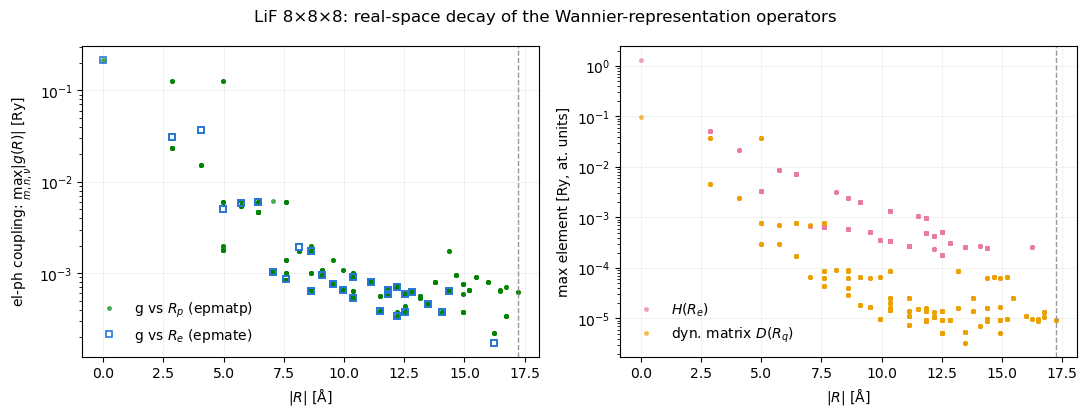

In [2]:
fig, (ax_g, ax_hd) = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)

# epmate/epmatp share many symmetry-equivalent (|R|, max|g|) rows — draw the
# sparser epmate as open markers on top so coincident points stay visible.
styles = {
    "g vs $R_e$ (epmate)": dict(marker="s", ms=5, mfc="none", mew=1.2, zorder=3),
    "g vs $R_p$ (epmatp)": dict(marker="o", ms=3.5, mew=0, alpha=0.7),
    "$H(R_e)$": dict(marker="o", ms=3.5, mew=0, alpha=0.7),
    "dyn. matrix $D(R_q)$": dict(marker="o", ms=3.5, mew=0, alpha=0.7),
}
panels = [
    (ax_g, ["g vs $R_p$ (epmatp)", "g vs $R_e$ (epmate)"],
     "el-ph coupling: $\\max_{m,n,\\nu}|g(R)|$ [Ry]"),
    (ax_hd, ["$H(R_e)$", "dyn. matrix $D(R_q)$"],
     "max element [Ry, at. units]"),
]
for ax, labels, ylabel in panels:
    for label in labels:
        d, color = data[label]
        ax.semilogy(d[:, 0], d[:, 1], ls="none", color=color, label=label, **styles[label])
    ax.set_xlabel("$|R|$ [Å]")
    ax.set_ylabel(ylabel)
    ax.legend(frameon=False)
    ax.grid(True, which="major", alpha=0.25, lw=0.5)
    ax.set_axisbelow(True)
    ax.axvline(max(data[l][0][:, 0].max() for l in labels), color="0.6", lw=1, ls="--")

fig.suptitle("LiF 8×8×8: real-space decay of the Wannier-representation operators")
fig.tight_layout()
fig.savefig("epmatwp-decay.png", dpi=150, bbox_inches="tight")
plt.show()

Conslusion: $H(R_e)$ and the force constants fall ~4 decades and sit near their floors at the boundary — bands and phonons are well converged at 8³. The coupling itself drops only ~2.5–3 decades, and its $R_p$ tail visibly **flattens** around $10^{-3}$–$10^{-4}$ Ry instead of reaching a noise floor. That truncated tail is the honest scale of what the 8³ supercell discards from `epmatwp`, and its magnitude (~1–10 meV in vertex units) is consistent with the ~10 meV 6³→8³ shift measured at the $E_0$ level. A slowly decaying remainder in a polar material after dipole-only long-range subtraction is the known signature of quadrupole (and higher-multipole) terms that the Vogl form doesn't remove. Geometric shrinkage still bounds the 8³→10³ step to a fraction of the 6³→8³ jump — but the flat tail means "converged to orders of magnitude" would be an overclaim for $g$; the defensible statement is the measured jump plus this bounded-remainder argument.